# 03. Opportunity Sizing — what is the mobile shipping-step leak worth?

**Question:** if mobile shoppers passed the shipping step as often as desktop shoppers, how much more revenue would Northline have made in Q4?

**Method:** extra orders = mobile checkouts × (benchmark pass rate − mobile pass rate) × share of those who go on to buy. Multiply by mobile average order value. Give a **range** of benchmarks, not one number, and report **gross and net** (after returns and cancellations).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLEAN = Path(r"E:\Northline\clean")

sessions = pd.read_parquet(CLEAN / "sessions.parquet", columns=["session_id", "user_id", "device"])
users = pd.read_parquet(CLEAN / "users.parquet", columns=["user_id", "loyalty_member"])
orders = pd.read_parquet(CLEAN / "orders.parquet")
ev = pd.read_parquet(CLEAN / "events.parquet", columns=["session_id", "event_name", "event_ts", "cart_value"],
                     filters=[("event_name", "in", ["begin_checkout", "add_shipping_info", "purchase"])])

## Checkout sessions and shipping-step pass rate by device

In [2]:
first = ev.groupby(["session_id", "event_name"], observed=True).event_ts.min().unstack()
co = first[first.begin_checkout.notna()].copy()
co["passed_shipping"] = co.add_shipping_info.notna() & (co.add_shipping_info >= co.begin_checkout)
co["purchased"] = co.passed_shipping & co.purchase.notna()
co = co.join(sessions.set_index("session_id")).reset_index().merge(users, on="user_id", how="left")

by_dev = co.groupby("device", observed=True).agg(
    checkouts=("passed_shipping", "size"),
    pass_rate=("passed_shipping", "mean"),
)
# of those who pass shipping, how many buy?
by_dev["buy_after_shipping"] = co[co.passed_shipping].groupby("device", observed=True).purchased.mean()
by_dev

,checkouts,pass_rate,buy_after_shipping
device,,,
desktop,6896,0.89,0.83
mobile,11114,0.77,0.84
tablet,1434,0.82,0.84


In [3]:
mob = co.merge(orders[["session_id", "order_revenue", "net_revenue"]], on="session_id", how="left")
mobile_orders = mob[(mob.device == "mobile") & mob.purchased]
AOV_GROSS = mobile_orders.order_revenue.mean()
NET_RATIO = orders.net_revenue.sum() / orders.order_revenue.sum()

MOBILE_CHECKOUTS = by_dev.loc["mobile", "checkouts"]
MOBILE_PASS = by_dev.loc["mobile", "pass_rate"]
DOWNSTREAM = by_dev.loc["mobile", "buy_after_shipping"]
print(f"Mobile checkouts in Q4:        {MOBILE_CHECKOUTS:,}")
print(f"Mobile shipping pass rate:     {MOBILE_PASS:.1%}")
print(f"Buy after passing shipping:    {DOWNSTREAM:.1%}")
print(f"Mobile AOV (gross):            ${AOV_GROSS:,.2f}")
print(f"Net / gross revenue ratio:     {NET_RATIO:.1%}")

Mobile checkouts in Q4:        11,114
Mobile shipping pass rate:     77.4%
Buy after passing shipping:    84.2%
Mobile AOV (gross):            $115.88
Net / gross revenue ratio:     82.5%


## Benchmarks — what's a fair target for mobile?

| Scenario | Benchmark | Why |
|---|---|---|
| Conservative | Match **mobile loyalty members** | Same device, but they never see a shipping fee: removes *only* the fee effect |
| Base | Close **half** the gap to desktop | Some of the gap is genuine device behavior (small screens, browsing on the go) |
| Optimistic | Match **desktop** | Full parity |

In [4]:
desktop_pass = by_dev.loc["desktop", "pass_rate"]
mobile_member_pass = co[(co.device == "mobile") & co.loyalty_member].passed_shipping.mean()

scen = pd.DataFrame({
    "benchmark_pass_rate": {
        "Conservative: mobile loyalty members (no fee)": mobile_member_pass,
        "Base: half the gap to desktop": MOBILE_PASS + (desktop_pass - MOBILE_PASS) / 2,
        "Optimistic: desktop parity": desktop_pass,
    }})
scen["gap_pts"] = (scen.benchmark_pass_rate - MOBILE_PASS) * 100
scen["extra_orders"] = MOBILE_CHECKOUTS * (scen.benchmark_pass_rate - MOBILE_PASS) * DOWNSTREAM
scen["gross_revenue"] = scen.extra_orders * AOV_GROSS
scen["net_revenue"] = scen.gross_revenue * NET_RATIO
scen["% of Q4 gross"] = scen.gross_revenue / orders.order_revenue.sum() * 100
scen.round({"extra_orders": 0})

,benchmark_pass_rate,gap_pts,extra_orders,gross_revenue,net_revenue,% of Q4 gross
Conservative: mobile loyalty members (no fee),0.81,3.82,358.00,"41,489.13","34,247.73",2.47
Base: half the gap to desktop,0.83,5.71,534.00,"61,938.34","51,127.78",3.69
Optimistic: desktop parity,0.89,11.42,"1,069.00","123,876.68","102,255.56",7.39


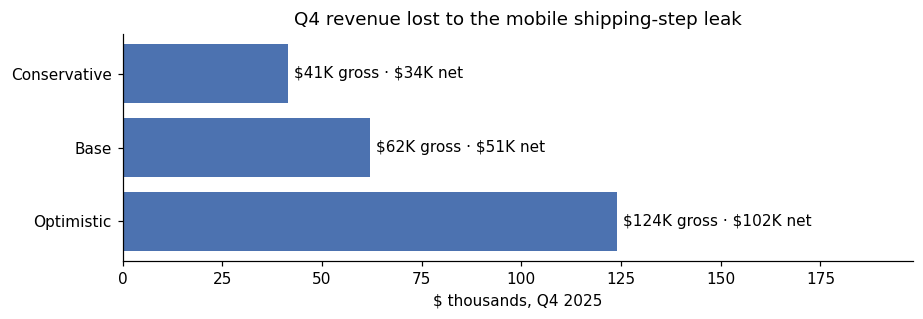

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3))
labels = [s.split(":")[0] for s in scen.index]
b = ax.barh(labels[::-1], scen.gross_revenue[::-1] / 1000, color="#4C72B0")
ax.bar_label(b, labels=[rf"\${v/1000:,.0f}K gross · \${n/1000:,.0f}K net" for v, n in
                        zip(scen.gross_revenue[::-1], scen.net_revenue[::-1])], padding=4)
ax.set_xlabel("$ thousands, Q4 2025"); ax.set_xlim(0, scen.gross_revenue.max() / 1000 * 1.6)
ax.set_title("Q4 revenue lost to the mobile shipping-step leak")
plt.tight_layout(); plt.show()

## Sensitivity — how much does the answer depend on the inputs?

The base case uses Q4 averages. If the share who buy after shipping or AOV were different, the estimate moves like this:

In [6]:
base_gap = scen.iloc[1].benchmark_pass_rate - MOBILE_PASS
grid = pd.DataFrame(index=[f"AOV ${a:,.0f}" for a in (AOV_GROSS * np.array([0.85, 1, 1.15]))],
                    columns=[f"buy after shipping {d:.0%}" for d in (DOWNSTREAM + np.array([-0.05, 0, 0.05]))])
for i, a in enumerate(AOV_GROSS * np.array([0.85, 1, 1.15])):
    for j, d in enumerate(DOWNSTREAM + np.array([-0.05, 0, 0.05])):
        grid.iloc[i, j] = MOBILE_CHECKOUTS * base_gap * d * a
grid.astype(float).map(lambda v: f"${v/1000:,.0f}K")

,buy after shipping 79%,buy after shipping 84%,buy after shipping 89%
AOV $99,$50K,$53K,$56K
AOV $116,$58K,$62K,$66K
AOV $133,$67K,$71K,$75K


## What it means

The base case is the number to quote, framed as a range:

In [9]:
lo, base, hi = scen.gross_revenue
print(f"Mobile shipping-step leak: ~${base/1000:,.0f}K gross (${scen.net_revenue.iloc[1]/1000:,.0f}K net) in Q4,")
print(f"range ${lo/1000:,.0f}K–${hi/1000:,.0f}K gross, "
      f"about {scen['% of Q4 gross'].iloc[1]:.1f}% of Q4 gross revenue.")
print(f"That's ~{scen.extra_orders.iloc[1]:,.0f} extra orders in one quarter.")

Mobile shipping-step leak: ~$62K gross ($51K net) in Q4,
range $41K–$124K gross, about 3.7% of Q4 gross revenue.
That's ~534 extra orders in one quarter.


**Caveats**
- This is Q4, the peak quarter: don't multiply by 4 for a yearly number.
- It assumes rescued shoppers spend like current mobile buyers. They're more likely small-cart shoppers, so the true value may sit toward the low end.
- It's an upper bound on what a *checkout* fix can do. A lower free-shipping threshold might recover more but costs margin.